In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn import svm
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

In [ ]:
mail_data = pd.read_csv('/spam_ham_dataset.csv')

In [ ]:
mail_data

,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\r\nthis deal is t...,0
...,...,...,...,...
5166,1518,ham,Subject: put the 10 on the ft\r\nthe transport...,0
5167,404,ham,Subject: 3 / 4 / 2000 and following noms\r\nhp...,0
5168,2933,ham,Subject: calpine daily gas nomination\r\n>\r\n...,0
5169,1409,ham,Subject: industrial worksheets for august 2000...,0


In [ ]:
mail_data.shape

(5171, 4)

In [ ]:
mail_data.isnull().sum().sum()

np.int64(0)

In [ ]:
mail_data['Unnamed: 0'].isnull().sum().sum()

np.int64(0)

In [ ]:
mail_data['label'].isnull().sum().sum()

np.int64(0)

In [ ]:
mail_data['label_num'].isnull().sum().sum()

np.int64(0)

In [ ]:
mail_data['text'].isnull().sum().sum()

np.int64(0)

In [ ]:
mail_data.groupby('label')['label'].count()

,label
label,
ham,3672
spam,1499


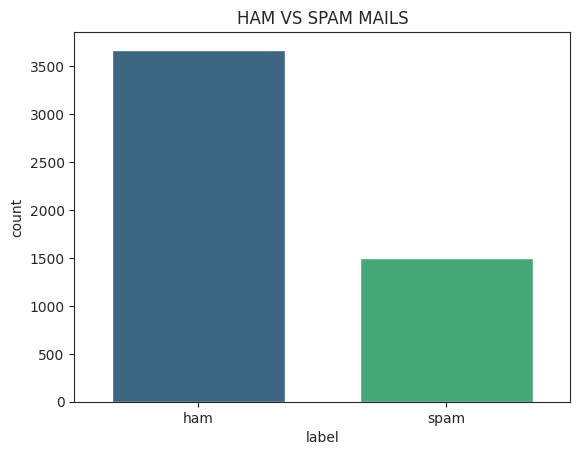

In [ ]:
sns.set_style('ticks')
sns.countplot(data = mail_data, x ='label', width = 0.7, palette = 'viridis', hue = 'label')
plt.title('HAM VS SPAM MAILS')
plt.show()

In [ ]:
mapping = {'ham': 1, 'spam': 0}
mail_data['label'] = mail_data['label'].map(mapping)

In [ ]:
mail_data

,Unnamed: 0,label,text,label_num
0,605,1,Subject: enron methanol ; meter # : 988291\r\n...,0
1,2349,1,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,3624,1,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,4685,0,"Subject: photoshop , windows , office . cheap ...",1
4,2030,1,Subject: re : indian springs\r\nthis deal is t...,0
...,...,...,...,...
5166,1518,1,Subject: put the 10 on the ft\r\nthe transport...,0
5167,404,1,Subject: 3 / 4 / 2000 and following noms\r\nhp...,0
5168,2933,1,Subject: calpine daily gas nomination\r\n>\r\n...,0
5169,1409,1,Subject: industrial worksheets for august 2000...,0


In [ ]:
#Now lets separate the dataset into label and text
X = mail_data['text']
Y = mail_data['label_num']

In [ ]:
print(X)

0       Subject: enron methanol ; meter # : 988291\r\n...
1       Subject: hpl nom for january 9 , 2001\r\n( see...
2       Subject: neon retreat\r\nho ho ho , we ' re ar...
3       Subject: photoshop , windows , office . cheap ...
4       Subject: re : indian springs\r\nthis deal is t...
                              ...                        
5166    Subject: put the 10 on the ft\r\nthe transport...
5167    Subject: 3 / 4 / 2000 and following noms\r\nhp...
5168    Subject: calpine daily gas nomination\r\n>\r\n...
5169    Subject: industrial worksheets for august 2000...
5170    Subject: important online banking alert\r\ndea...
Name: text, Length: 5171, dtype: object


In [ ]:
print(Y)

0       0
1       0
2       0
3       1
4       0
       ..
5166    0
5167    0
5168    0
5169    0
5170    1
Name: label_num, Length: 5171, dtype: int64


In [ ]:
#Split X and Y data into training and testing
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 3)

In [ ]:
#Print shape
print(X.shape)

(5171,)


In [ ]:
print(X_train.shape)

(4136,)


In [ ]:
print(X_test.shape)

(1035,)


In [ ]:
print(Y_train.shape)

(4136,)


In [ ]:
print(Y_test.shape)

(1035,)


In [ ]:
param_to_convert_text = TfidfVectorizer(min_df = 1, stop_words = 'english', lowercase = True)

In [ ]:
X_train_converted = param_to_convert_text.fit_transform(X_train)
X_test_converted = param_to_convert_text.transform(X_test)

In [ ]:
print(X_train_converted)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 270337 stored elements and shape (4136, 45076)>
  Coords	Values
  (0, 38946)	0.01685805739459834
  (0, 21882)	0.15822963156663866
  (0, 43279)	0.15279926161032253
  (0, 13656)	0.0442446131354994
  (0, 26040)	0.06237658334565303
  (0, 13860)	0.05933334362320758
  (0, 29166)	0.04619404683559966
  (0, 32538)	0.08215570069958765
  (0, 42165)	0.1301153463744466
  (0, 38303)	0.12444307809779734
  (0, 37119)	0.09423749412823572
  (0, 28593)	0.09000082107218554
  (0, 16156)	0.3284546097301849
  (0, 12663)	0.17173706521192092
  (0, 1179)	0.13387711316973605
  (0, 27743)	0.44166331773844575
  (0, 2645)	0.12444307809779734
  (0, 1177)	0.13387711316973605
  (0, 2844)	0.11843023142166303
  (0, 31384)	0.14556222812251965
  (0, 836)	0.14556222812251965
  (0, 3875)	0.14556222812251965
  (0, 16637)	0.24438399643390496
  (0, 19429)	0.14556222812251965
  (0, 517)	0.14556222812251965
  :	:
  (4135, 18858)	0.08197239345561386
  (4135, 41043)	0.0

In [ ]:
print(X_test_converted)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 62621 stored elements and shape (1035, 45076)>
  Coords	Values
  (0, 128)	0.06751196703924772
  (0, 2304)	0.08000502840495706
  (0, 7104)	0.1559461605148248
  (0, 8299)	0.16362994369867745
  (0, 8642)	0.2439826982095742
  (0, 10169)	0.4514832887567547
  (0, 10897)	0.1559461605148248
  (0, 11338)	0.21730933930033283
  (0, 11781)	0.11999471032560592
  (0, 14304)	0.12307453197378486
  (0, 15436)	0.10462714395790063
  (0, 17653)	0.10593459620258483
  (0, 18948)	0.13837580346969947
  (0, 19347)	0.10885583499169456
  (0, 19349)	0.11999471032560592
  (0, 20980)	0.09026858994936217
  (0, 21661)	0.08219406011652994
  (0, 23267)	0.08786187709365104
  (0, 26798)	0.19410412869894605
  (0, 27061)	0.08684642663655563
  (0, 28045)	0.22723675877287497
  (0, 29300)	0.055923031890344886
  (0, 30502)	0.11999471032560592
  (0, 32218)	0.2137183924250268
  (0, 32223)	0.11907011031567737
  :	:
  (1034, 25360)	0.08526464626280715
  (1034, 25771)	0.

In [ ]:
Y_train = Y_train.astype('int')
Y_test = Y_test.astype('int')

In [ ]:
model1 = DecisionTreeClassifier()
model1.fit(X_train_converted, Y_train)

DecisionTreeClassifier()

In [ ]:
train_data_prediction = model1.predict(X_train_converted)

In [ ]:
accuracy_decision_train = accuracy_score(Y_train, train_data_prediction)
print('The accuracy for the training data using decision trees classifier is:', accuracy_decision_train)

The accuracy for the training data using decision trees classifier is: 1.0


In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold
k = 5
scores = cross_val_score(model1, X_train_converted, Y_train, cv=k)
print('The cross validation score for each fold is:', scores)

The cross validation score for each fold is: [0.95289855 0.93954051 0.94195889 0.94679565 0.93712213]


In [ ]:
1

1

In [ ]:
test_data_prediction = model1.predict(X_test_converted)
accuracy_decision_test = accuracy_score(Y_test, test_data_prediction)
print('The accuracy for the test data using decision trees classifier is:', accuracy_decision_test)

The accuracy for the test data using decision trees classifier is: 0.9468599033816425


In [ ]:
precision = precision_score(Y_test, test_data_prediction)
print('The precision score for Decision Tree test dataset is', round(precision, 2))

The precision score for Decision Tree test dataset is 0.9


In [ ]:
re_score = recall_score(Y_test, test_data_prediction)
print('The recall score for Decision Tree test dataset is', round(precision, 2))

The recall score for Decision Tree test dataset is 0.9


In [ ]:
model2 = svm.SVC(kernel='poly')
model2.fit(X_train_converted, Y_train)

SVC(kernel='poly')

In [ ]:
model2_train_data_pred = model2.predict(X_train_converted)

accuracy_model2_train = accuracy_score(Y_train, model2_train_data_pred)
print('The accuracy for the training data using Support Vector classifier is:', accuracy_model2_train)

The accuracy for the training data using Support Vector classifier is: 1.0


In [ ]:
k = 6
valscores = cross_val_score(model2, X_train_converted, Y_train, cv=k)
print('The cross validation score for each fold is:', valscores)

The cross validation score for each fold is: [0.80869565 0.79565217 0.79825835 0.81422351 0.79825835 0.79825835]


In [ ]:
model2_test_data_pred = model2.predict(X_test_converted)

accuracy_model2_test = accuracy_score(Y_test, model2_test_data_pred)
print('The accuracy for the training data using Support Vector classifier is:', accuracy_model2_test)

The accuracy for the training data using Support Vector classifier is: 0.8038647342995169


In [ ]:
model3 = LogisticRegression()
model3.fit(X_train_converted, Y_train)

LogisticRegression()

In [ ]:
model3_train_data_pred = model3.predict(X_train_converted)

accuracy_model3_train = accuracy_score(Y_train, model3_train_data_pred)
print('The accuracy for the training data using Logistic Regression classifier is:', accuracy_model3_train)

The accuracy for the training data using Logistic Regression classifier is: 0.9968568665377177


In [ ]:
k = 5
valscores2 = cross_val_score(model3, X_train_converted, Y_train, cv=k)
print('The cross validation score for each fold is:', valscores2)

The cross validation score for each fold is: [0.98913043 0.98307134 0.98548972 0.98911729 0.98911729]


In [ ]:
model3_test_data_pred = model3.predict(X_test_converted)

accuracy_model3_test = accuracy_score(Y_test, model3_test_data_pred)
print('The accuracy for the training data using Logistic Regression classifier is:', accuracy_model3_test)

The accuracy for the training data using Logistic Regression classifier is: 0.9806763285024155


Now let's compare the results of the three models. From our analysis, all the three Machine learning Algorithm used in training the dataset in this project (which are: Decision Tree Classifier, SVC and Logistics Regression, )gives 100% accuracy on training data. While on test data, Decision tree classifier gives 96% accuracy, SVC gives 94% accuracy and logistic Regression gives 96% accuracy. Since Decision tree classifier and Logistic Regression are producing the best iinaccuracies, we will employ one of these model in building a Predictive System

Building A Model

In [ ]:
email=["URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C www.dbuk.net LCCLTD POBOX 4403LDMW1A7RW18"]
# Now let's transform the email to numeric data
email_input = param_to_convert_text.transform(email)

In [ ]:
# walking Prediction

prediction = model3.predict(email_input)

if(prediction==1):

 print(f"The result of the prediction is {prediction}, its a Ham mail")

else:

 print(f"The result of the prediction is {prediction}, its a spam mail")

The result of the prediction is [1], its a Ham mail


Saving The Model As a Pickle File For Deployment

In [ ]:
import pickle

#saving model three

with open('spam_model.pkl', 'wb') as file:
  pickle.dump(model3, file)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
from sklearn.pipeline import Pipeline

# Create a pipeline with both vectorizer and model
pipeline = Pipeline([
    ('tfidf', param_to_convert_text),
    ('classifier', model3)
])

# Save the complete pipeline
with open('spam_model.pkl', 'wb') as file:
    pickle.dump(pipeline, file)